**Датасет:** https://allisonhorst.github.io/palmerpenguins/

# Лабораторная работа №3. Кластеризация
### Отчет по практическому заданию курса «Машинное обучение»

### 1) Введение

- **Цель работы:** изучить кластеризацию, оценить качество разбиения и интерпретировать группы.
- **Постановка задачи:**
  1. Загрузить промеры пингвинов архипелага Палмера и описать размерность, типы, пропуски и распределения.
  2. Проверить, осмысленна ли кластеризация, и отделить вид птицы от признаков расстояния.
  3. Обосновать стандартизацию.
  4. По матрице рассеяния, локтю и силуэту выбрать число кластеров.
  5. Построить K-средних и иерархию Уорда, сравнить метрики, расстояния и профили.
  6. Показать, как число кластеров меняет качество, и нарисовать группы на главных компонентах.
- **Датасет:** Palmer Penguins, измерения Адели, антарктического и папуанского пингвинов. В расстояние входят четыре промера. Вид используется только как внешняя метка.

### 2) Описание датасета

Каждая строка — одна птица. Промеры: длина и высота клюва, длина плавника, масса тела. Остров и пол описывают место и биологию, но в расстояние не входят: иначе кластер может повторить остров, а не форму тела. Вид известен и нужен только для Rand, Жаккара и ARI.

Кластеризация осмыслена: размеры тела и клюва различают виды. Пропуски есть только в отдельных строках, это незаполненный промер, а не отдельная группа. Выбросы проверяются правилом полутора межквартильных размахов.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
)
from sklearn.metrics.cluster import pair_confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.autolayout"] = True

SEED = 42
np.random.seed(SEED)

RU = {
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Высота клюва, мм",
    "flipper_length_mm": "Длина плавника, мм",
    "body_mass_g": "Масса тела, г",
}
MEASURES = list(RU)
SPECIES = {"Adelie": "Адели", "Chinstrap": "Антарктический", "Gentoo": "Папуанский"}

raw = pd.read_csv("data/penguins.csv")
print("=" * 80)
print(f"Исходный файл: {raw.shape[0]} строк, {raw.shape[1]} столбцов")
print("=" * 80)
print(raw.dtypes.to_string())
print("\nПропуски:")
print(raw.isnull().sum().to_string())
print("Виды:")
print(raw["species"].map(SPECIES).value_counts().to_string())

df = raw.dropna(subset=MEASURES).reset_index(drop=True)
df["Вид"] = df["species"].map(SPECIES)
print(f"\nПосле удаления пустых промеров: {len(df)}")
print(f"Дубликатов по четырём промерам: {int(df.duplicated(subset=MEASURES).sum())}")

desc = df[MEASURES].describe().T
summary = pd.DataFrame({
    "Среднее": desc["mean"],
    "Станд. откл.": desc["std"],
    "Медиана": desc["50%"],
    "Минимум": desc["min"],
    "Максимум": desc["max"],
    "Асимметрия": df[MEASURES].skew(),
}).rename(index=RU).round(2)
print(summary.to_string())

outlier_rows, any_mask = [], np.zeros(len(df), dtype=bool)
for col in MEASURES:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    any_mask |= mask.to_numpy()
    outlier_rows.append({"Признак": RU[col], "Выбросов по IQR": int(mask.sum())})
print(pd.DataFrame(outlier_rows).to_string(index=False))
print(f"Птиц хотя бы с одним хвостом: {int(any_mask.sum())} из {len(df)}")

shapiro_rows = []
for col in MEASURES:
    stat_w, stat_p = shapiro(df[col])
    shapiro_rows.append({"Признак": RU[col], "W": stat_w, "p": stat_p})
print(pd.DataFrame(shapiro_rows).round(4).to_string(index=False))

Исходный файл: 344 строк, 7 столбцов
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object

Пропуски:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
Виды:
species
Адели             152
Папуанский        124
Антарктический     68

После удаления пустых промеров: 342
Дубликатов по четырём промерам: 0
                    Среднее  Станд. откл.  Медиана  Минимум  Максимум  Асимметрия
Длина клюва, мм       43.92          5.46    44.45     32.1      59.6        0.05
Высота клюва, мм      17.15          1.97    17.30     13.1      21.5       -0.14
Длина плавника, мм   200.92         14.06   197.00    172.0     231.0        0.35
Масса тела, г       4201.75        801.95  4050.00   2700.0    6300.0        0.47
           Признак  

### Пояснение к описанию данных

- В файле 344 птицы. Пустые промеры есть у двух строк, они удаляются. Пол и остров для расстояния не нужны, их пропуски на кластеризацию не влияют.
- Масса записана в граммах, клюв и плавник — в миллиметрах. Средние отличаются на два порядка, поэтому без стандартизации расстояние почти целиком определяется массой.
- Асимметрия умеренная. Тест Шапиро–Уилка на смеси трёх видов может отвергать нормальность одного столбца, даже если внутри вида распределение близко к колоколу: смесь сама создаёт плечи.
- Хвостов по правилу 1,5 IQR мало. Это крупные или мелкие птицы, а не ошибки ввода. Строки остаются.

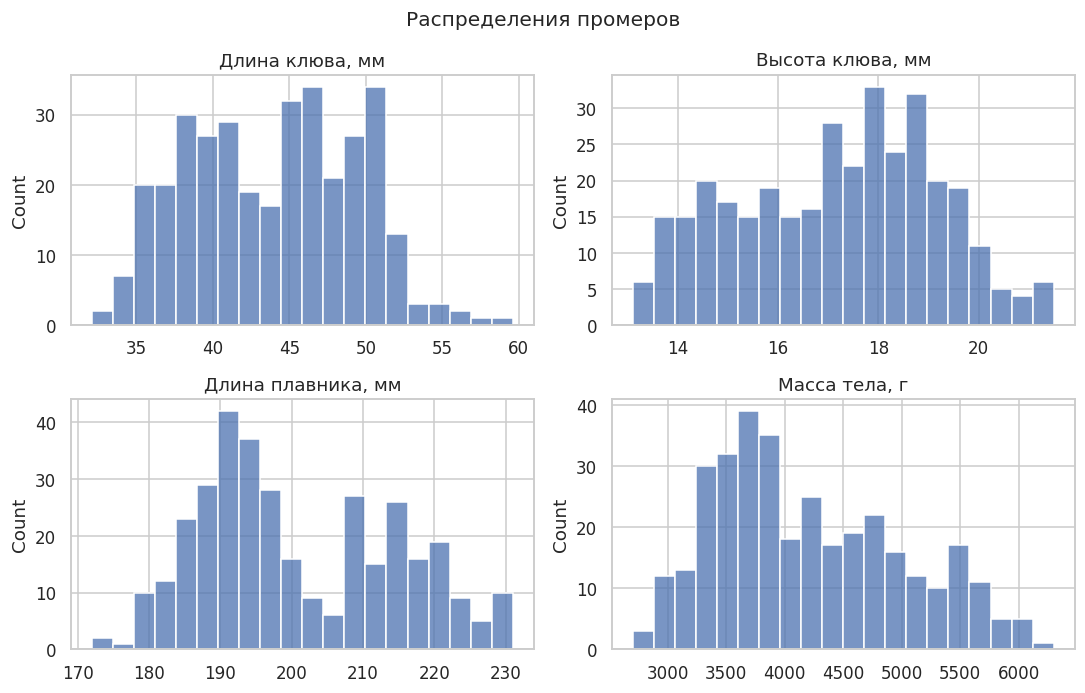

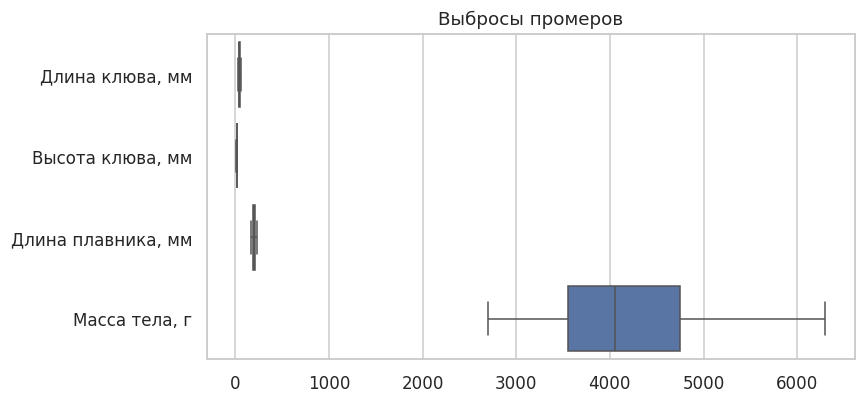

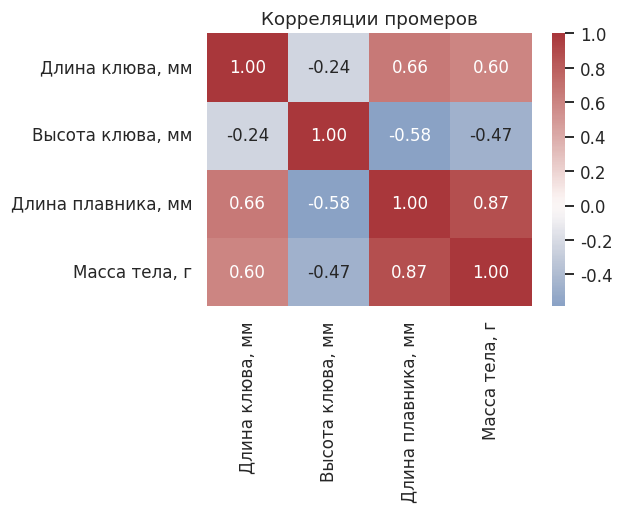

Коэффициент вариации:
Длина клюва, мм       0.124
Высота клюва, мм      0.115
Длина плавника, мм    0.070
Масса тела, г         0.191


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
for ax, col in zip(axes.ravel(), MEASURES):
    sns.histplot(df[col], bins=20, ax=ax, color="#4C72B0")
    ax.set_title(RU[col])
    ax.set_xlabel("")
fig.suptitle("Распределения промеров")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df[MEASURES].rename(columns=RU), orient="h", ax=ax, color="#4C72B0")
ax.set_title("Выбросы промеров")
plt.show()

corr = df[MEASURES].corr().rename(index=RU, columns=RU)
fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Корреляции промеров")
plt.show()
cv = (df[MEASURES].std() / df[MEASURES].mean()).rename(RU)
print("Коэффициент вариации:")
print(cv.round(3).to_string())

### Информационная значимость признаков

Ни один промер не постоянен: коэффициент вариации у всех заметный, у массы и клюва он больше, чем у высоты клюва. Длина плавника и масса сильно связаны: это одна ось размера тела. Длина и высота клюва связаны слабее и несут форму клюва, а не только размер. Для расстояния связка «плавник + масса» тянет птицу вдоль размера, а клюв может отделить виды одинакового размера. Все четыре промера остаются.

### 3) Предобработка

K-средних и метод Уорда используют евклидово расстояние. Масса в тысячах граммов иначе задавит клюв в десятках миллиметров.

`StandardScaler` вычитает среднее и делит на стандартное отклонение каждого промера. После этого вклад признака равен тому, насколько птица необычна относительно разброса этого промера. MinMax оставил бы влияние крайних птиц на границы отрезка. Логарифм не нужен: асимметрия умеренная, отрицательных промеров нет, а шкала после стандартизации уже сопоставима. Масштаб считается по всем птицам, которые кластеризуются. Вид в матрицу `X` не входит.

Средние после стандартизации:
Длина клюва, мм       0.0
Высота клюва, мм     -0.0
Длина плавника, мм   -0.0
Масса тела, г         0.0
Стандартные отклонения:
Длина клюва, мм       1.0
Высота клюва, мм      1.0
Длина плавника, мм    1.0
Масса тела, г         1.0
Компонента  Доля дисперсии  Накопленная доля
      ГК 1           0.688             0.688
      ГК 2           0.193             0.882
      ГК 3           0.091             0.973
      ГК 4           0.027             1.000


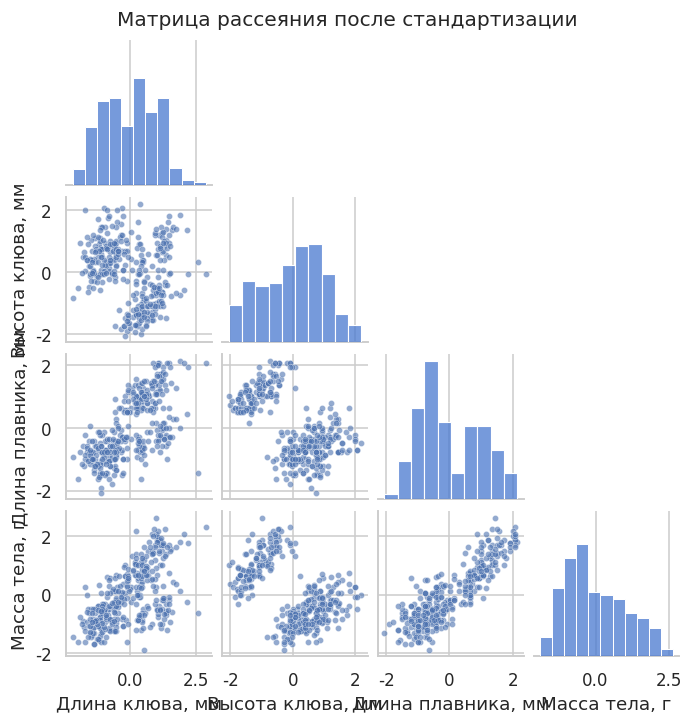

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(df[MEASURES].to_numpy(dtype=float))
scaled = pd.DataFrame(X, columns=[RU[c] for c in MEASURES])
print("Средние после стандартизации:")
print(scaled.mean().round(6).to_string())
print("Стандартные отклонения:")
print(scaled.std(ddof=0).round(6).to_string())

pca_full = PCA(random_state=SEED).fit(X)
explained = pd.DataFrame({
    "Компонента": [f"ГК {i}" for i in range(1, 5)],
    "Доля дисперсии": pca_full.explained_variance_ratio_,
    "Накопленная доля": np.cumsum(pca_full.explained_variance_ratio_),
})
print(explained.round(3).to_string(index=False))
sns.pairplot(scaled, corner=True, diag_kind="hist", plot_kws={"s": 16, "alpha": 0.6, "color": "#4C72B0"}, height=1.6)
plt.suptitle("Матрица рассеяния после стандартизации", y=1.02)
plt.show()

### Пояснение к матрице рассеяния и выбору методов

Две первые компоненты собирают основную долю дисперсии. На плоскостях видна плотная группа крупных птиц с длинным плавником и облако птиц меньшего размера. Группы компактные и сопоставимы по разбросу, сильного фона одиночных точек нет.

- **K-средних** подходит для таких сгущений. `n_init=10` снижает риск неудачного центра.
- **Иерархия Уорда** минимизирует ту же внутрикластерную дисперсию и показывает на дендрограмме, устойчиво ли верхнее разделение.

DBSCAN был бы уместен при рваной плотности. Здесь два плотных облака, поэтому основные методы — K-средних и Уорд.

### 4) Подбор числа кластеров

 k  Инерция K-means  Силуэт K-means  Калински–Харабас  Дэвис–Боулдин  Силуэт Уорд
 2          565.708           0.532           482.191          0.714        0.532
 3          379.393           0.447           441.677          0.944        0.454
 4          300.400           0.400           400.410          0.944        0.418
 5          232.605           0.379           411.243          0.971        0.363
 6          204.393           0.368           382.570          0.995        0.335
 7          187.029           0.331           352.553          1.075        0.305
 8          170.980           0.296           334.045          1.151        0.259
k по силуэту K-means: 2
k по силуэту Уорда: 2


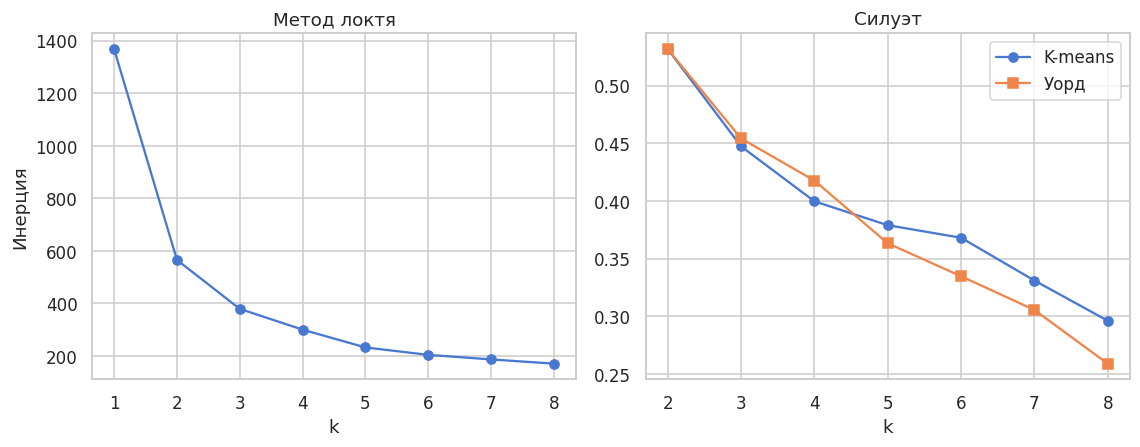

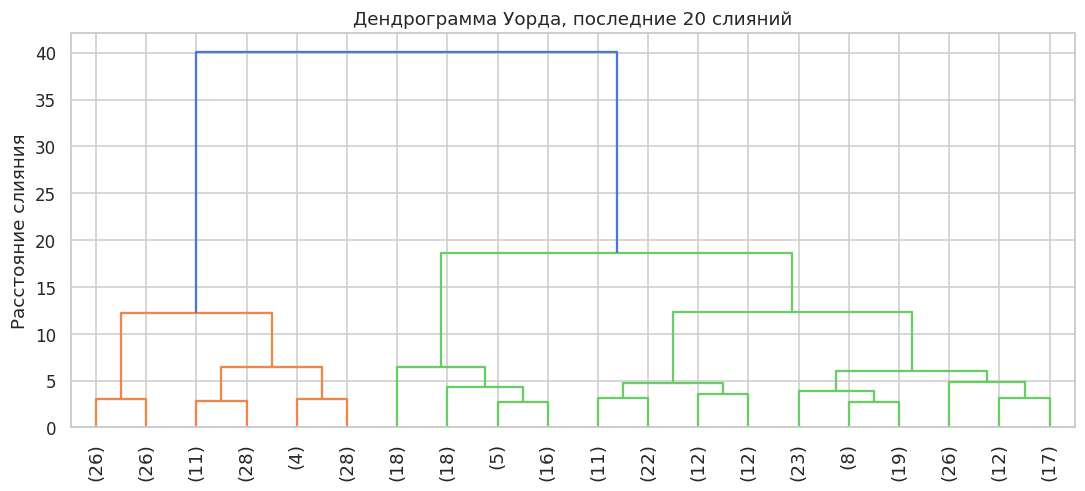

In [4]:
inertia = []
for k in range(1, 9):
    inertia.append(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).inertia_)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    rows.append({
        "k": k,
        "Инерция K-means": km.inertia_,
        "Силуэт K-means": silhouette_score(X, km.labels_),
        "Калински–Харабас": calinski_harabasz_score(X, km.labels_),
        "Дэвис–Боулдин": davies_bouldin_score(X, km.labels_),
        "Силуэт Уорд": silhouette_score(X, ag.labels_),
    })
selection = pd.DataFrame(rows)
print(selection.round(3).to_string(index=False))
k_km = int(selection.loc[selection["Силуэт K-means"].idxmax(), "k"])
k_ag = int(selection.loc[selection["Силуэт Уорд"].idxmax(), "k"])
print(f"k по силуэту K-means: {k_km}")
print(f"k по силуэту Уорда: {k_ag}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].plot(range(1, 9), inertia, marker="o")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[1].plot(selection["k"], selection["Силуэт K-means"], marker="o", label="K-means")
axes[1].plot(selection["k"], selection["Силуэт Уорд"], marker="s", label="Уорд")
axes[1].set_title("Силуэт")
axes[1].set_xlabel("k")
axes[1].legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.6))
Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, color_threshold=0.7 * max(Z[:, 2]), ax=ax)
ax.set_title("Дендрограмма Уорда, последние 20 слияний")
ax.set_ylabel("Расстояние слияния")
plt.show()

### Пояснение к выбору k

Силуэт максимален при двух кластерах. Индекс Калински–Харабаса тоже поддерживает компактное разделение, а не дробление на много групп. Локоть после двух кластеров становится пологим. Дендрограмма на верхнем уровне режется на две ветви. Оба метода дальше запускаются с k, который выбрал силуэт. Вид птицы в этот выбор не входит: три вида в таблице не заставляют ставить k = 3, если внутренний критерий видит два сгущения.

### 5) Две кластеризации и метрики

Внутренние метрики считаются в стандартизированном пространстве. Внешние сравнивают метку кластера с видом. Индекс Rand завышен, когда одна группа крупная, поэтому рядом стоит ARI. Парный Жаккар — доля пар, которые вместе и в кластере, и в виде, среди пар, которые вместе хотя бы в одном разбиении.

         Силуэт  Калински–Харабас  Дэвис–Боулдин   Rand    ARI  Жаккар по парам    NMI  Однородность  Полнота  V-мера
Метод                                                                                                                
K-means   0.532           482.191          0.714  0.824  0.655            0.673  0.767         0.622      1.0   0.767
Уорд      0.532           482.191          0.714  0.824  0.655            0.673  0.767         0.622      1.0   0.767
ARI между методами: 1.000
Геометрия K-means:
 Кластер  Размер  Среднее расстояние до центра  Максимум до центра
       0     219                         1.295               3.063
       1     123                         0.984               2.878
Расстояние между центрами K-means: [3.192]
Геометрия Уорда:
 Кластер  Размер  Среднее расстояние до центра  Максимум до центра
       0     219                         1.295               3.063
       1     123                         0.984               2.878
Расстояние между цент

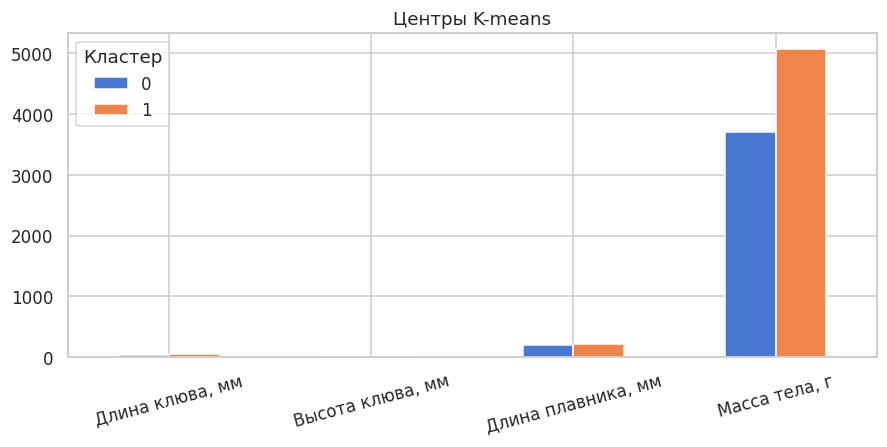

In [5]:
def pair_jaccard(y_true, y_pred):
    matrix = pair_confusion_matrix(y_true, y_pred)
    _, false_positive, false_negative, true_positive = matrix.ravel()
    denominator = true_positive + false_positive + false_negative
    return float(true_positive / denominator) if denominator else 0.0


def geometry(space, labels, centers):
    rows = []
    for cluster_id, center in enumerate(centers):
        points = space[labels == cluster_id]
        distance = np.linalg.norm(points - center, axis=1)
        rows.append({
            "Кластер": int(cluster_id),
            "Размер": int(len(points)),
            "Среднее расстояние до центра": float(distance.mean()),
            "Максимум до центра": float(distance.max()),
        })
    return pd.DataFrame(rows), pdist(centers)


def external_block(name, labels):
    return {
        "Метод": name,
        "Силуэт": silhouette_score(X, labels),
        "Калински–Харабас": calinski_harabasz_score(X, labels),
        "Дэвис–Боулдин": davies_bouldin_score(X, labels),
        "Rand": rand_score(df["Вид"], labels),
        "ARI": adjusted_rand_score(df["Вид"], labels),
        "Жаккар по парам": pair_jaccard(df["Вид"], labels),
        "NMI": normalized_mutual_info_score(df["Вид"], labels),
        "Однородность": homogeneity_score(df["Вид"], labels),
        "Полнота": completeness_score(df["Вид"], labels),
        "V-мера": v_measure_score(df["Вид"], labels),
    }


kmeans = KMeans(n_clusters=k_km, n_init=10, random_state=SEED).fit(X)
agg = AgglomerativeClustering(n_clusters=k_ag, linkage="ward").fit(X)
df["K-means"] = kmeans.labels_
df["Уорд"] = agg.labels_
agg_centers = np.vstack([X[agg.labels_ == cluster].mean(axis=0) for cluster in range(k_ag)])
km_geom, km_between = geometry(X, kmeans.labels_, kmeans.cluster_centers_)
ag_geom, ag_between = geometry(X, agg.labels_, agg_centers)
quality = pd.DataFrame([
    external_block("K-means", kmeans.labels_),
    external_block("Уорд", agg.labels_),
]).set_index("Метод")
print(quality.round(3).to_string())
print(f"ARI между методами: {adjusted_rand_score(kmeans.labels_, agg.labels_):.3f}")
print("Геометрия K-means:")
print(km_geom.round(3).to_string(index=False))
print("Расстояние между центрами K-means:", np.round(km_between, 3))
print("Геометрия Уорда:")
print(ag_geom.round(3).to_string(index=False))
print("Расстояние между центрами Уорда:", np.round(ag_between, 3))

centers_raw = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_raw, columns=[RU[c] for c in MEASURES]).round(1)
print("Центры K-means в исходных единицах:")
print(centers_df.to_string())
print("Состав видов, K-means:")
print(pd.crosstab(df["K-means"], df["Вид"]).to_string())
print("Состав видов, Уорд:")
print(pd.crosstab(df["Уорд"], df["Вид"]).to_string())
print("Медианы промеров, K-means:")
print(df.groupby("K-means")[MEASURES].median().rename(columns=RU).round(1).to_string())

fig, ax = plt.subplots(figsize=(8.2, 4.2))
centers_df.T.plot(kind="bar", ax=ax)
ax.set_title("Центры K-means")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Кластер")
plt.show()

### Пояснение к метрикам и профилям

Силуэт обоих методов равен **0,532**, индекс Калински–Харабаса — **482,2**, Дэвис–Боулдин — **0,714**. Это плотные и разделённые группы. Среднее расстояние до центра — **1,295** в большем кластере и **0,984** в меньшем, расстояние между центрами — **3,192**. ARI между K-средних и Уордом равен **1,000**: разбиения совпали, включая номера кластеров.

Внешние метрики тоже совпали: Rand **0,824**, ARI **0,655**, парный Жаккар **0,673**, NMI **0,767**, однородность **0,622**, полнота **1,000**, V-мера **0,767**. Полнота равна единице, потому что каждый вид целиком лежит в одном кластере. Однородность ниже: кластер 0 объединяет Адели (151) и антарктического пингвина (68). Кластер 1 — все 123 папуанских.

Центры в исходных единицах. Кластер 0: клюв **41,9 × 18,4** мм, плавник **191,8** мм, масса **3710,7** г. Кластер 1: клюв **47,5 × 15,0** мм, плавник **217,2** мм, масса **5076,0** г. Медианы повторяют ту же картину: 3700 г против 5000 г. Второй центр — крупная птица с длинным плавником и более плоским клювом, это папуанский пингвин.

### Влияние числа кластеров

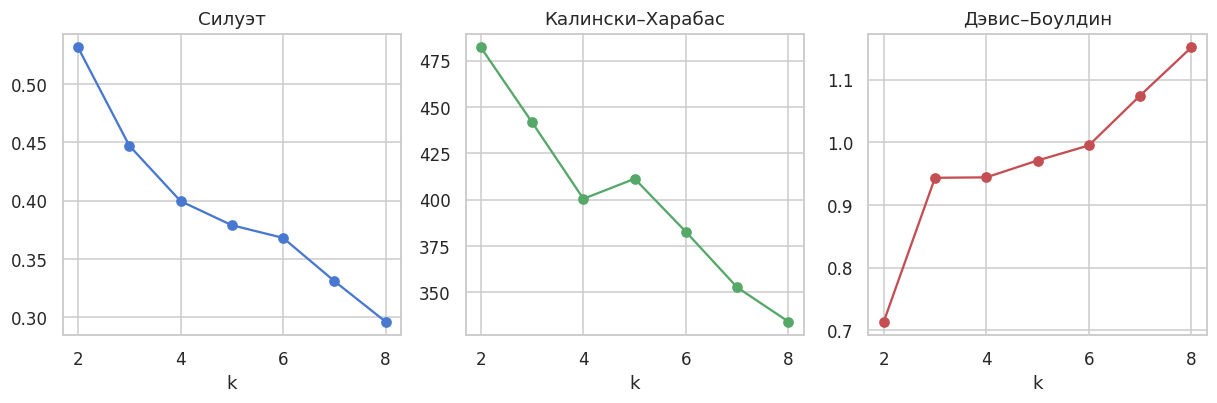

 k  Силуэт K-means  Калински–Харабас  Дэвис–Боулдин
 2           0.532           482.191          0.714
 3           0.447           441.677          0.944
 4           0.400           400.410          0.944
 5           0.379           411.243          0.971
 6           0.368           382.570          0.995
 7           0.331           352.553          1.075
 8           0.296           334.045          1.151
k=2: силуэт 0.532, ARI с видом 0.655
k=3: силуэт 0.447, ARI с видом 0.793


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.8))
axes[0].plot(selection["k"], selection["Силуэт K-means"], marker="o")
axes[0].set_title("Силуэт")
axes[1].plot(selection["k"], selection["Калински–Харабас"], marker="o", color="#55A868")
axes[1].set_title("Калински–Харабас")
axes[2].plot(selection["k"], selection["Дэвис–Боулдин"], marker="o", color="#C44E52")
axes[2].set_title("Дэвис–Боулдин")
for ax in axes:
    ax.set_xlabel("k")
plt.show()
print(selection[["k", "Силуэт K-means", "Калински–Харабас", "Дэвис–Боулдин"]].round(3).to_string(index=False))
for k in (2, 3):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    print(f"k={k}: силуэт {silhouette_score(X, labels):.3f}, ARI с видом {adjusted_rand_score(df['Вид'], labels):.3f}")

### Пояснение к чувствительности

При k = 2 силуэт **0,532**, при k = 3 он падает до **0,447**. Индекс Калински–Харабаса тоже максимален при двух кластерах (**482** против **442**), Дэвис–Боулдин минимален при двух (**0,714** против **0,944**).

ARI с видом при k = 3 вырастает до **0,793** с **0,655**: меньшие виды начинают расходиться. Внутренние критерии этого шага не просят. Число кластеров в работе остаётся равным 2.

### 6) Визуализация

Доля дисперсии на рисунке: 0.882
                     ГК 1   ГК 2
Длина клюва, мм     0.455  0.597
Высота клюва, мм   -0.400  0.798
Длина плавника, мм  0.576  0.002
Масса тела, г       0.548  0.084


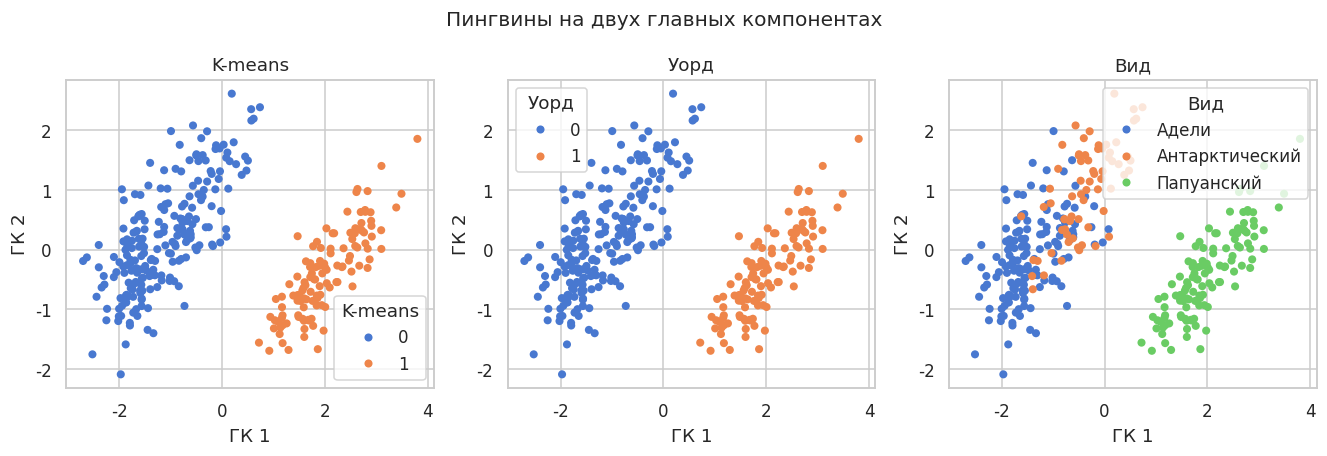

In [7]:
pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(X)
print(f"Доля дисперсии на рисунке: {pca.explained_variance_ratio_.sum():.3f}")
loadings = pd.DataFrame(pca.components_.T, index=[RU[c] for c in MEASURES], columns=["ГК 1", "ГК 2"]).round(3)
print(loadings.to_string())
plot_df = pd.DataFrame({
    "ГК 1": xy[:, 0], "ГК 2": xy[:, 1],
    "K-means": df["K-means"].astype(str),
    "Уорд": df["Уорд"].astype(str),
    "Вид": df["Вид"],
})
fig, axes = plt.subplots(1, 3, figsize=(12.2, 4.2))
for ax, hue in zip(axes, ("K-means", "Уорд", "Вид")):
    sns.scatterplot(data=plot_df, x="ГК 1", y="ГК 2", hue=hue, s=28, ax=ax, linewidth=0)
    ax.set_title(hue)
fig.suptitle("Пингвины на двух главных компонентах")
plt.show()

### Пояснение к рисунку

Первая компонента собирает размер: масса и длина плавника. Вторая держит форму клюва. Два цвета K-средних ложатся вдоль размера. Папуанские птицы занимают один край и совпадают с одним кластером. Адели и антарктический пингвин сидят в другом облаке и расходятся по клюву слабее, чем по размеру, поэтому при k = 2 остаются вместе. Уорд повторяет эту границу.

### 7) Заключение

В файле 344 птицы. После удаления двух строк с пустыми промерами остаётся **342**. Дубликатов по четырём промерам нет, выбросов по правилу 1,5 IQR нет. Масса в граммах и клюв в миллиметрах выровнены стандартизацией. Вид в матрицу расстояний не входит.

Две первые компоненты собирают **88,2%** дисперсии. Силуэт и дендрограмма выбирают **k = 2**. K-средних при `n_init = 10` и иерархия Уорда дают одно и то же разбиение: силуэт **0,532**, ARI между методами **1,000**. Кластер из 123 птиц — папуанский пингвин (центр: плавник 217 мм, масса 5076 г). Кластер из 219 птиц — Адели и антарктический пингвин (плавник 192 мм, масса 3711 г). Полнота относительно вида равна **1,000**, ARI — **0,655**: два меньших вида делят один кластер. При k = 3 ARI растёт до **0,793**, а силуэт падает до **0,447**.

Для этих промеров достаточно K-средних: центры читаются в миллиметрах и граммах, а Уорд повторяет ту же границу. Оба метода применимы к двум плотным сгущениям.

### 8) Список источников

1. Horst A. M., Hill A. P., Gorman K. B. palmerpenguins: Palmer Archipelago penguin data. 2020. https://allisonhorst.github.io/palmerpenguins/
2. Pedregosa F. et al. Scikit-learn: Machine Learning in Python. JMLR, 12, 2011, pp. 2825–2830.
3. MacQueen J. Some methods for classification and analysis of multivariate observations. Proc. 5th Berkeley Symposium, 1967, pp. 281–297.
4. Ward J. H. Hierarchical grouping to optimize an objective function. JASA, 58, 1963, pp. 236–244.
5. Rousseeuw P. J. Silhouettes. Journal of Computational and Applied Mathematics, 20, 1987, pp. 53–65.
6. Caliński T., Harabasz J. A dendrite method for cluster analysis. Communications in Statistics, 3, 1974, pp. 1–27.
7. Davies D. L., Bouldin D. W. A cluster separation measure. IEEE TPAMI, 1, 1979, pp. 224–227.
8. Scikit-learn. Clustering. https://scikit-learn.org/stable/modules/clustering.html

### 9) Приложение

Полный листинг — ячейки этого ноутбука. Данные: `data/penguins.csv`. Seed равен 42, у K-средних `n_init=10`.